In [1]:
from evaluation import ComprehensiveTestSuite
import os
import joblib

## Evaluation of the Standard Filters

In [2]:
import os
import joblib
from evaluation import ComprehensiveTestSuite

# ==========================================
# 1. PATH CONFIGURATION (STATIC THRESHOLDS)
# ==========================================
static_results_path = 'tuning_results/completed_studies_BEST.pkl'

# ==========================================
# 2. LOAD THE RESULTS
# ==========================================
if os.path.exists(static_results_path):
    # Load the dictionary generated by the original terminal script
    completed_studies = joblib.load(static_results_path)
    print(f" Successfully loaded STATIC optimization results from: {static_results_path}")
    
    # ------------------------------------------
    # 3. EXTRACT OPTIMAL THRESHOLDS
    # ------------------------------------------
    # pH Optimal Parameters
    best_ph_raw_drift = completed_studies['ph']['raw'].best_params['raw_drift_threshold']
    best_ph_raw_decay = completed_studies['ph']['raw'].best_params['raw_leakage']
    best_ph_agg_pers = completed_studies['ph']['agg'].best_params['agg_persistence']
    best_ph_agg_drift = completed_studies['ph']['agg'].best_params['agg_abs_drift']

    # Temperature Optimal Parameters
    best_temp_raw_drift = completed_studies['temp']['raw'].best_params['raw_drift_threshold']
    best_temp_raw_decay = completed_studies['temp']['raw'].best_params['raw_leakage']
    best_temp_agg_pers = completed_studies['temp']['agg'].best_params['agg_persistence']
    best_temp_agg_drift = completed_studies['temp']['agg'].best_params['agg_abs_drift']

    # Combined Optimal Parameters
    best_comb_raw_drift_ph = completed_studies['combined']['raw'].best_params['raw_drift_ph']
    best_comb_raw_drift_temp = completed_studies['combined']['raw'].best_params['raw_drift_temp']
    best_comb_raw_decay = completed_studies['combined']['raw'].best_params['raw_leakage']
    best_comb_agg_pers = completed_studies['combined']['agg'].best_params['agg_persistence']
    best_comb_agg_drift_ph = completed_studies['combined']['agg'].best_params['agg_abs_drift_ph']
    best_comb_agg_drift_temp = completed_studies['combined']['agg'].best_params['agg_abs_drift_temp']

    # ------------------------------------------
    # 4. PRINT SUMMARY TABLE
    # ------------------------------------------
    print("\n" + "="*45)
    print(" FINAL OPTIMIZED STATIC THRESHOLDS & DECAY")
    print("="*45)
    print(f"pH Raw Drift:             {best_ph_raw_drift:.4f}")
    print(f"pH Raw Decay (d):         {best_ph_raw_decay:.4f}") 
    print(f"pH Agg Persistence:       {best_ph_agg_pers}")
    print(f"pH Agg Drift:             {best_ph_agg_drift:.4f}")
    print("-" * 45)
    print(f"Temp Raw Drift:           {best_temp_raw_drift:.4f}")
    print(f"Temp Raw Decay (d):       {best_temp_raw_decay:.4f}") 
    print(f"Temp Agg Persistence:     {best_temp_agg_pers}")
    print(f"Temp Agg Drift:           {best_temp_agg_drift:.4f}")
    print("-" * 45)
    print(f"Combined Raw Drift (pH):  {best_comb_raw_drift_ph:.4f}")
    print(f"Combined Raw Drift (T):   {best_comb_raw_drift_temp:.4f}")
    print(f"Combined Raw Decay (d):   {best_comb_raw_decay:.4f}") 
    print(f"Combined Agg Persistence: {best_comb_agg_pers}")
    print(f"Combined Agg Drift (pH):  {best_comb_agg_drift_ph:.4f}")
    print(f"Combined Agg Drift (T):   {best_comb_agg_drift_temp:.4f}")
    print("="*45 + "\n")

    # ------------------------------------------
    # 5. RUN FINAL STATIC BENCHMARK
    # ------------------------------------------
    static_optimized_thresholds = {
        'ph_raw_drift': best_ph_raw_drift, 'ph_raw_leakage': best_ph_raw_decay,
        'ph_agg_pers': best_ph_agg_pers, 'ph_agg_drift': best_ph_agg_drift,
        'temp_raw_drift': best_temp_raw_drift, 'temp_raw_leakage': best_temp_raw_decay,
        'temp_agg_pers': best_temp_agg_pers, 'temp_agg_drift': best_temp_agg_drift,
        'comb_raw_drift_ph': best_comb_raw_drift_ph, 'comb_raw_drift_temp': best_comb_raw_drift_temp,
        'comb_raw_leakage': best_comb_raw_decay, 'comb_agg_pers': best_comb_agg_pers,
        'comb_agg_drift_ph': best_comb_agg_drift_ph, 'comb_agg_drift_temp': best_comb_agg_drift_temp
    }

    print("Initializing Final Robustness Test (STATIC ARCHITECTURE)")
    print("-> This will output both Global Summaries AND Disease-Level Breakdowns.")
    
    tester = ComprehensiveTestSuite(static_optimized_thresholds, use_z_score=False)
    tester.run_full_suite(num_iterations=10)

else:
    print(f" ERROR: Results file not found at {static_results_path}")
    print("Please run 'python parameter_tuning.py' in your terminal first.")

 Successfully loaded STATIC optimization results from: tuning_results/completed_studies_BEST.pkl

 FINAL OPTIMIZED STATIC THRESHOLDS & DECAY
pH Raw Drift:             0.9600
pH Raw Decay (d):         0.9895
pH Agg Persistence:       1
pH Agg Drift:             0.0500
---------------------------------------------
Temp Raw Drift:           3.8000
Temp Raw Decay (d):       0.9392
Temp Agg Persistence:     1
Temp Agg Drift:           0.6000
---------------------------------------------
Combined Raw Drift (pH):  0.9600
Combined Raw Drift (T):   5.0000
Combined Raw Decay (d):   0.9408
Combined Agg Persistence: 2
Combined Agg Drift (pH):  0.0500
Combined Agg Drift (T):   0.6000

Initializing Final Robustness Test (STATIC ARCHITECTURE)
-> This will output both Global Summaries AND Disease-Level Breakdowns.
Starting STATIC THRESHOLD Multi-Run Parallel Test Suite (10 iterations) on 16 cores...
 --- Starting Iteration 1 ---
[SYSTEMIC_ALKALOSIS_PH] Velocity: 2.0h | Random Onset: Hour 4.9 | Peak: H

## Evaluation of the Z-Scoring Filters

In [3]:
import os
import joblib
from evaluation import ComprehensiveTestSuite

# ==========================================
# 1. PATH CONFIGURATION (Z-SCORE)
# ==========================================
zscore_results_path = 'tuning_results/completed_zscore_studies.pkl'

# ==========================================
# 2. LOAD THE RESULTS
# ==========================================
if os.path.exists(zscore_results_path):
    # Load the dictionary generated by the Z-score terminal script
    completed_z_studies = joblib.load(zscore_results_path)
    print(f" Successfully loaded Z-Score optimization results from: {zscore_results_path}")
    
    # ------------------------------------------
    # 3. EXTRACT OPTIMAL MULTIPLIERS
    # ------------------------------------------
    # pH Optimal Parameters
    best_ph_k_raw = completed_z_studies['ph']['raw'].best_params['k_raw_multiplier']
    best_ph_raw_leakage = completed_z_studies['ph']['raw'].best_params['raw_leakage']
    best_ph_agg_pers = completed_z_studies['ph']['agg'].best_params['agg_persistence']
    best_ph_k_agg = completed_z_studies['ph']['agg'].best_params['k_agg_multiplier']

    # Temperature Optimal Parameters
    best_temp_k_raw = completed_z_studies['temp']['raw'].best_params['k_raw_multiplier']
    best_temp_raw_leakage = completed_z_studies['temp']['raw'].best_params['raw_leakage']
    best_temp_agg_pers = completed_z_studies['temp']['agg'].best_params['agg_persistence']
    best_temp_k_agg = completed_z_studies['temp']['agg'].best_params['k_agg_multiplier']

    # Combined Optimal Parameters
    best_comb_k_raw_ph = completed_z_studies['combined']['raw'].best_params['k_raw_ph']
    best_comb_k_raw_temp = completed_z_studies['combined']['raw'].best_params['k_raw_temp']
    best_comb_raw_leakage = completed_z_studies['combined']['raw'].best_params['raw_leakage']
    best_comb_agg_pers = completed_z_studies['combined']['agg'].best_params['agg_persistence']
    best_comb_k_agg_ph = completed_z_studies['combined']['agg'].best_params['k_agg_ph']
    best_comb_k_agg_temp = completed_z_studies['combined']['agg'].best_params['k_agg_temp']

    # ------------------------------------------
    # 4. PRINT SUMMARY TABLE
    # ------------------------------------------
    print("\n" + "="*45)
    print(" FINAL OPTIMIZED Z-SCORE MULTIPLIERS (k)")
    print("="*45)
    print(f"pH Raw k-multiplier:        {best_ph_k_raw:.4f}")
    print(f"pH Raw Decay (d):           {best_ph_raw_leakage:.4f}")
    print(f"pH Agg Persistence:         {best_ph_agg_pers}")
    print(f"pH Agg k-multiplier:        {best_ph_k_agg:.4f}")
    print("-" * 45)
    print(f"Temp Raw k-multiplier:      {best_temp_k_raw:.4f}")
    print(f"Temp Raw Decay (d):         {best_temp_raw_leakage:.4f}")
    print(f"Temp Agg Persistence:       {best_temp_agg_pers}")
    print(f"Temp Agg k-multiplier:      {best_temp_k_agg:.4f}")
    print("-" * 45)
    print(f"Combined Raw k (pH):        {best_comb_k_raw_ph:.4f}")
    print(f"Combined Raw k (T):         {best_comb_k_raw_temp:.4f}")
    print(f"Combined Raw Decay (d):     {best_comb_raw_leakage:.4f}")
    print(f"Combined Agg Persistence:   {best_comb_agg_pers}")
    print(f"Combined Agg k (pH):        {best_comb_k_agg_ph:.4f}")
    print(f"Combined Agg k (T):         {best_comb_k_agg_temp:.4f}")
    print("="*45 + "\n")

    # ------------------------------------------
    # 5. RUN FINAL Z-SCORE BENCHMARK
    # ------------------------------------------
    zscore_optimized_thresholds = {
        'ph_k_raw': best_ph_k_raw, 'ph_k_agg': best_ph_k_agg,
        'ph_raw_leakage': best_ph_raw_leakage, 'ph_agg_pers': best_ph_agg_pers,
        'temp_k_raw': best_temp_k_raw, 'temp_k_agg': best_temp_k_agg,
        'temp_raw_leakage': best_temp_raw_leakage, 'temp_agg_pers': best_temp_agg_pers,
        'comb_k_raw_ph': best_comb_k_raw_ph, 'comb_k_raw_temp': best_comb_k_raw_temp,
        'comb_k_agg_ph': best_comb_k_agg_ph, 'comb_k_agg_temp': best_comb_k_agg_temp,
        'comb_raw_leakage': best_comb_raw_leakage, 'comb_agg_pers': best_comb_agg_pers
    }

    print("Initializing Final Robustness Test (Z-SCORE ARCHITECTURE)")
    print("-> This will output both Global Summaries AND Disease-Level Breakdowns.")
    
    tester = ComprehensiveTestSuite(zscore_optimized_thresholds, use_z_score=True)
    # The updated run_full_suite now handles the disease-level printouts automatically!
    tester.run_full_suite(num_iterations=10)

else:
    print(f" ERROR: Z-Score Results file not found at {zscore_results_path}")
    print("Please run 'python tune_z_scores.py' in your terminal first.")

 Successfully loaded Z-Score optimization results from: tuning_results/completed_zscore_studies.pkl

 FINAL OPTIMIZED Z-SCORE MULTIPLIERS (k)
pH Raw k-multiplier:        7.9000
pH Raw Decay (d):           0.8530
pH Agg Persistence:         3
pH Agg k-multiplier:        5.9000
---------------------------------------------
Temp Raw k-multiplier:      8.0000
Temp Raw Decay (d):         0.8629
Temp Agg Persistence:       1
Temp Agg k-multiplier:      2.1000
---------------------------------------------
Combined Raw k (pH):        6.5000
Combined Raw k (T):         7.4000
Combined Raw Decay (d):     0.8653
Combined Agg Persistence:   3
Combined Agg k (pH):        5.0000
Combined Agg k (T):         2.6000

Initializing Final Robustness Test (Z-SCORE ARCHITECTURE)
-> This will output both Global Summaries AND Disease-Level Breakdowns.
Starting Z-SCORE Multi-Run Parallel Test Suite (10 iterations) on 16 cores...
 --- Starting Iteration 1 ---
[DVT_TEMP] Velocity: 8.0h | Random Onset: Hour 6.7 |

In [4]:
import os
import joblib
from evaluation import TargetedCohortTestSuite

def run_targeted_static_evaluation(cohort_name):
    results_path = f'tuning_results/completed_static_{cohort_name}.pkl'
    
    if not os.path.exists(results_path):
        print(f"ERROR: {results_path} not found. Please run targeted_parameter_tuning.py first.")
        return
        
    print(f"\n{'='*75}")
    print(f" LOADING STATIC COMBINED PARAMETERS FOR: {cohort_name.upper()}")
    print(f"{'='*75}")
    
    studies = joblib.load(results_path)
    
    # Extract ONLY the optimal Combined parameters
    best_params = {
        'comb_raw_drift_ph': studies['combined']['raw'].best_params['raw_drift_ph'],
        'comb_raw_drift_temp': studies['combined']['raw'].best_params['raw_drift_temp'],
        'comb_raw_leakage': studies['combined']['raw'].best_params['raw_leakage'],
        'comb_agg_pers': studies['combined']['agg'].best_params['agg_persistence'],
        'comb_agg_drift_ph': studies['combined']['agg'].best_params['agg_abs_drift_ph'],
        'comb_agg_drift_temp': studies['combined']['agg'].best_params['agg_abs_drift_temp']
    }
    
    print(f"  Raw Drift (pH/Temp): {best_params['comb_raw_drift_ph']:.4f} / {best_params['comb_raw_drift_temp']:.4f}")
    print(f"  Raw Decay (d):       {best_params['comb_raw_leakage']:.4f}") 
    print(f"  Agg Persistence:     {best_params['comb_agg_pers']}")
    print(f"  Agg Drift (pH/Temp): {best_params['comb_agg_drift_ph']:.4f} / {best_params['comb_agg_drift_temp']:.4f}\n")
    
    # Initialize the new Targeted Evaluator (use_z_score=False for Static)
    tester = TargetedCohortTestSuite(cohort_name, best_params, use_z_score=False)
    
    # Run the stochastic evaluation (10 iterations is usually mathematically solid)
    tester.run_targeted_suite(num_iterations=10)


# ==========================================
# EXECUTE EVALUATIONS
# ==========================================
print("Initializing Final Targeted Robustness Test (STATIC ARCHITECTURE)")

run_targeted_static_evaluation('post_op')
run_targeted_static_evaluation('diabetes')

ImportError: cannot import name 'TargetedCohortTestSuite' from 'evaluation' (/home/davide/Sim_01_Toy_Tests/evaluation.py)

In [ ]:
import os
import joblib
from evaluation import TargetedCohortTestSuite

def run_targeted_zscore_evaluation(cohort_name):
    results_path = f'tuning_results/completed_zscore_{cohort_name}.pkl'
    
    if not os.path.exists(results_path):
        print(f"ERROR: {results_path} not found. Please run targeted_zscore_tuning.py first.")
        return
        
    print(f"\n{'='*75}")
    print(f" LOADING Z-SCORE COMBINED PARAMETERS FOR: {cohort_name.upper()}")
    print(f"{'='*75}")
    
    studies = joblib.load(results_path)
    
    # Extract ONLY the optimal Combined Z-Score multipliers
    best_params = {
        'comb_k_raw_ph': studies['combined']['raw'].best_params['k_raw_ph'],
        'comb_k_raw_temp': studies['combined']['raw'].best_params['k_raw_temp'],
        'comb_raw_leakage': studies['combined']['raw'].best_params['raw_leakage'],
        'comb_agg_pers': studies['combined']['agg'].best_params['agg_persistence'],
        'comb_k_agg_ph': studies['combined']['agg'].best_params['k_agg_ph'],
        'comb_k_agg_temp': studies['combined']['agg'].best_params['k_agg_temp']
    }
    
    print(f"  Raw k-Multipliers (pH/Temp): {best_params['comb_k_raw_ph']:.4f} / {best_params['comb_k_raw_temp']:.4f}")
    print(f"  Raw Decay (d):               {best_params['comb_raw_leakage']:.4f}") 
    print(f"  Agg Persistence:             {best_params['comb_agg_pers']}")
    print(f"  Agg k-Multipliers (pH/Temp): {best_params['comb_k_agg_ph']:.4f} / {best_params['comb_k_agg_temp']:.4f}\n")
    
    # Initialize the new Targeted Evaluator (use_z_score=True for Z-Scoring)
    tester = TargetedCohortTestSuite(cohort_name, best_params, use_z_score=True)
    
    # Run the stochastic evaluation
    tester.run_targeted_suite(num_iterations=10)


# ==========================================
# EXECUTE EVALUATIONS
# ==========================================
print("Initializing Final Targeted Robustness Test (Z-SCORE ARCHITECTURE)")

run_targeted_zscore_evaluation('post_op')
run_targeted_zscore_evaluation('diabetes')

Generating Curated Archetypal Architecture Grid (Clean Y-Axis)...
[DKA_PH] Velocity: 6.0h | Random Onset: Hour 6.1 | Peak: Hour 12.1
Found 3 distinct archetypes to plot!


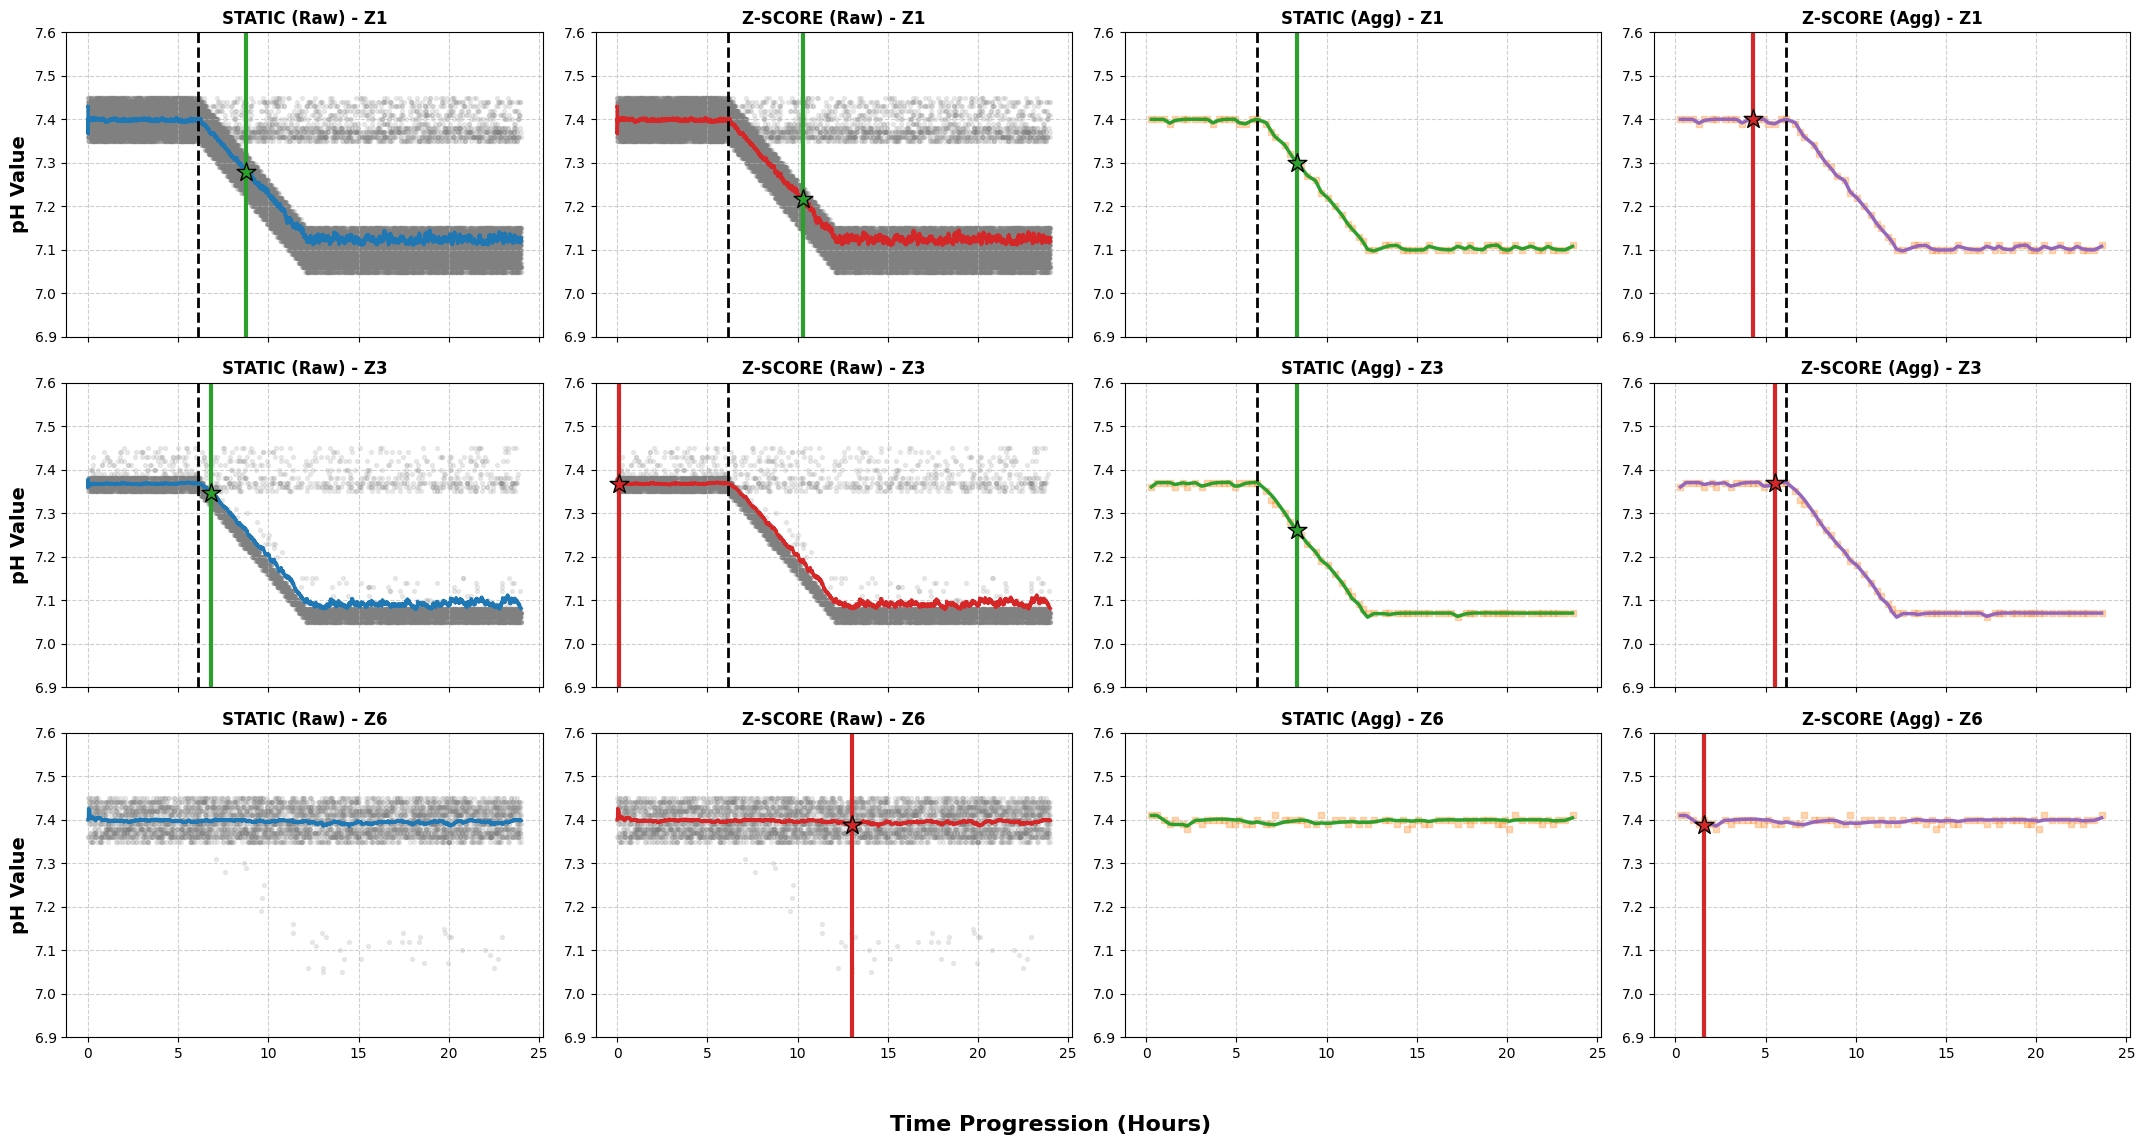

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# import concurrent.futures

# from diseases import DiseaseSimulator
# from drift_detection import AnomalyDetector

# print("Generating Curated Archetypal Architecture Grid (Clean Y-Axis)...")

# # ==========================================
# # 1. GENERATE A SINGLE PATIENT (DKA)
# # ==========================================
# disease_to_sim = 'dka_ph'
# safe_start_time = 14400 

# simulator = DiseaseSimulator() 
# raw_df, agg_df, t_start = simulator.run_single_disease(
#     alpha=0.3, 
#     beta=0.10, 
#     disease_key=disease_to_sim, 
#     safe_start_time=safe_start_time
# )

# target_zones = simulator.diseases[disease_to_sim]['zones']
# all_zones = list(range(1, 21))
# healthy_zones = [z for z in all_zones if z not in target_zones]

# # ==========================================
# # 2. INITIALIZE DETECTORS
# # ==========================================
# static_detector = AnomalyDetector(
#     alpha=0.3, beta=0.10, use_z_score=False,
#     raw_drift_threshold=best_ph_raw_drift, 
#     raw_leakage=best_ph_raw_decay,
#     agg_persistence=best_ph_agg_pers,
#     agg_abs_drift=best_ph_agg_drift
# )

# zscore_detector = AnomalyDetector(
#     alpha=0.3, beta=0.10, use_z_score=True,
#     k_raw_multiplier=best_ph_k_raw, 
#     raw_leakage=best_ph_raw_leakage,
#     k_agg_multiplier=best_ph_k_agg,
#     agg_persistence=best_ph_agg_pers
# )

# # ==========================================
# # 3. RUN ALL 4 DETECTIONS IN PARALLEL
# # ==========================================
# with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:
#     f_stat_raw = executor.submit(static_detector.detect_raw_stream, raw_df)
#     f_stat_agg = executor.submit(static_detector.detect_aggregated_stream, agg_df)
#     f_z_raw = executor.submit(zscore_detector.detect_raw_stream, raw_df)
#     f_z_agg = executor.submit(zscore_detector.detect_aggregated_stream, agg_df)
    
#     stat_raw_df, stat_raw_alerts = f_stat_raw.result()
#     stat_agg_df, stat_agg_alerts = f_stat_agg.result()
#     z_raw_df, z_raw_alerts = f_z_raw.result()
#     z_agg_df, z_agg_alerts = f_z_agg.result()

# # Convert time to hours
# stat_raw_df['Time_Hours'] = stat_raw_df['Time_Seconds'] / 3600
# stat_agg_df['Time_Hours'] = stat_agg_df['Time_Seconds_End'] / 3600
# z_raw_df['Time_Hours'] = z_raw_df['Time_Seconds'] / 3600
# z_agg_df['Time_Hours'] = z_agg_df['Time_Seconds_End'] / 3600
# t_start_hr = t_start / 3600

# # ==========================================
# # 4. SMART SELECTION ENGINE (ARCHETYPES)
# # ==========================================
# selected_archetypes = {}

# # A. True Positive (Target zone that successfully caught the disease)
# for z in target_zones:
#     if z in stat_raw_alerts and stat_raw_alerts[z] >= t_start:
#         selected_archetypes['True Positive'] = z
#         break

# # B. Premature False Positive (Target zone that alarmed BEFORE disease started)
# for z in target_zones:
#     if (z in z_raw_alerts and z_raw_alerts[z] < t_start) or (z in stat_raw_alerts and stat_raw_alerts[z] < t_start):
#         if z not in selected_archetypes.values():
#             selected_archetypes['Premature FP'] = z
#             break

# # C. Spatial Leakage False Positive (Healthy zone that falsely alarmed)
# for z in healthy_zones:
#     if z in z_raw_alerts or z in stat_raw_alerts or z in z_agg_alerts:
#         if z not in selected_archetypes.values():
#             selected_archetypes['Spatial Leakage'] = z
#             break

# # D. True Negative (Healthy zone that perfectly stayed quiet)
# for z in healthy_zones:
#     if z not in z_raw_alerts and z not in stat_raw_alerts and z not in z_agg_alerts and z not in stat_agg_alerts:
#         if z not in selected_archetypes.values():
#             selected_archetypes['True Negative'] = z
#             break

# nrows = len(selected_archetypes)
# print(f"Found {nrows} distinct archetypes to plot!")

# # ==========================================
# # 5. GENERATE THE CURATED VISUALIZATION
# # ==========================================
# with plt.style.context("seaborn-v0_8-muted"):
#     fig, axes = plt.subplots(nrows, 4, figsize=(22, 4 * nrows), sharex=True, squeeze=False)

#     for i, (archetype_name, zone) in enumerate(selected_archetypes.items()):
#         is_target = zone in target_zones
#         zone_label = f"Z{zone}"

#         zr_s = stat_raw_df[stat_raw_df['Zone'] == zone]
#         za_s = stat_agg_df[stat_agg_df['Zone'] == zone]
#         zr_z = z_raw_df[z_raw_df['Zone'] == zone]
#         za_z = z_agg_df[z_agg_df['Zone'] == zone]
        
#         # --- HELPER FUNCTION FOR PLOTTING EACH CELL ---
#         def plot_cell(ax, df, alerts_dict, is_agg, title, line_color, scatter_color, scatter_marker):
#             time_col = 'Time_Hours'
#             val_col = 'Median_Val' if is_agg else 'Value'
            
#             # Plot background points and Kalman line
#             ax.scatter(df[time_col], df[val_col], alpha=0.3 if is_agg else 0.15, 
#                        color=scatter_color, s=25 if is_agg else 8, marker=scatter_marker)
#             ax.plot(df[time_col], df['Filtered_Value'], color=line_color, linewidth=2.5)
            
#             # Only draw the black disease onset line if this zone actually gets the disease
#             if is_target:
#                 ax.axvline(x=t_start_hr, color='black', linestyle='--', linewidth=2)
            
#             # Plot Alert
#             if zone in alerts_dict:
#                 t_det = alerts_dict[zone] / 3600
#                 is_valid = is_target and (t_det >= t_start_hr)
#                 alert_color = '#2ca02c' if is_valid else '#d62728' 
#                 ax.axvline(x=t_det, color=alert_color, linestyle='-', linewidth=3)
                
#                 y_val = df['Filtered_Value'].iloc[np.argmin(np.abs(df[time_col] - t_det))] if not df.empty else 7.4
#                 ax.scatter(t_det, y_val, color=alert_color, marker='*', s=200, edgecolor='black', zorder=10)
            
#             ax.set_title(f"{title} - {zone_label}", fontweight='bold', color='black')
#             ax.set_ylim(6.9, 7.6) 
#             ax.grid(True, linestyle='--', alpha=0.6)

#             # Add simple "pH Value" label to the first column only
#             if "Raw" in title and "STATIC" in title:
#                 ax.set_ylabel("pH Value", fontsize=14, fontweight='bold', color='black')

#         # Draw the 4 columns
#         plot_cell(axes[i, 0], zr_s, stat_raw_alerts, False, "STATIC (Raw)", '#1f77b4', 'gray', 'o')
#         plot_cell(axes[i, 1], zr_z, z_raw_alerts, False, "Z-SCORE (Raw)", '#d62728', 'gray', 'o')
#         plot_cell(axes[i, 2], za_s, stat_agg_alerts, True, "STATIC (Agg)", '#2ca02c', '#ff7f0e', 's')
#         plot_cell(axes[i, 3], za_z, z_agg_alerts, True, "Z-SCORE (Agg)", '#9467bd', '#ff7f0e', 's')

#     fig.supxlabel('Time Progression (Hours)', fontsize=16, fontweight='bold')
#     # fig.suptitle("Diagnostic Archetypes Comparison (DKA Pathology)", fontsize=22, fontweight='bold')
    
#     plt.tight_layout(rect=[0.02, 0.03, 1, 0.96])
#     plt.show()